In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

import warnings
warnings.filterwarnings("ignore")

In [2]:
#Load datasets
import pandas as pd

customers = pd.read_csv("customer_datasets_cleaned(1).csv")

orders = pd.read_excel("orders_datasets_cleaned.xlsx")

order_items = pd.read_excel("order_items_datasets_cleaned.xlsx")

products = pd.read_excel("products_datasets_cleaned.xlsx")

reviews = pd.read_excel("order_reviews_datasets_cleaned.xlsx")

geolocation = pd.read_excel("geolocation_datasets_cleaned.xlsx")

In [3]:
print("Customers:", customers.shape)
print("Orders:", orders.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)
print("Reviews:", reviews.shape)

Customers: (90000, 5)
Orders: (99999, 13)
Order Items: (150004, 19)
Products: (32951, 16)
Reviews: (97019, 7)


In [4]:
def clean_columns(df):
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
        .str.replace("-", "_")
    )
    return df

customers = clean_columns(customers)
orders = clean_columns(orders)
order_items = clean_columns(order_items)
products = clean_columns(products)
reviews = clean_columns(reviews)

In [5]:
print("ORDERS:")
print(orders.columns.tolist())

print("\nORDER ITEMS:")
print(order_items.columns.tolist())

print("\nPRODUCTS:")
print(products.columns.tolist())

print("\nREVIEWS:")
print(reviews.columns.tolist())

ORDERS:
['order_id', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_delay', 'delivery_status', 'unnamed:_11', 'unnamed:_12']

ORDER ITEMS:
['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'outlier', 'gross_amount', 'discount_amount', 'net_product_amount', 'total_cost_including_shipping', 'unnamed:_12', 'unnamed:_13', 'unnamed:_14', 'unnamed:_15', 'unnamed:_16', 'unnamed:_17', 'unnamed:_18']

PRODUCTS:
['product_id', 'category_name', 'sub_category_name', 'product_weight_g', 'brand', 'cost_price', 'selling_price', 'stock_availability', 'selling_price_<_cost_price', 'profit', 'profit_margin', 'column1', 'unnamed:_12', 'unnamed:_13', 'unnamed:_14', 'unnamed:_15']

REVIEWS:
['t', 'order_id', 'review_score', 'review_comment_message', 'review_date', 'unnamed:_5', 'unnamed:_6']


In [7]:
customers = customers.drop_duplicates()
orders = orders.drop_duplicates()
order_items = order_items.drop_duplicates()
products = products.drop_duplicates()
reviews = reviews.drop_duplicates()

In [8]:
orders["order_status"] = (
    orders["order_status"]
    .astype(str)
    .str.strip()
    .str.lower()
)

orders["is_cancelled"] = orders["order_status"].isin(
    ["cancelled", "canceled"]
).astype(int)

In [9]:
orders["delivery_group"] = np.where(
    orders["delivery_delay"] > 0,
    "Delayed",
    "On Time"
)

In [10]:
h1_summary = orders.groupby("delivery_group").agg(
    total_orders=("order_id", "nunique"),
    cancelled_orders=("is_cancelled", "sum")
)

h1_summary["cancellation_rate"] = (
    h1_summary["cancelled_orders"] /
    h1_summary["total_orders"]
)

h1_summary["cancellation_rate_%"] = (
    h1_summary["cancellation_rate"] * 100
)

print(h1_summary)

                total_orders  cancelled_orders  cancellation_rate  \
delivery_group                                                      
Delayed                66681                 0            0.00000   
On Time                33318              5048            0.15151   

                cancellation_rate_%  
delivery_group                       
Delayed                    0.000000  
On Time                   15.150969  


In [11]:
delayed = h1_summary.loc["Delayed"]
on_time = h1_summary.loc["On Time"]

count = np.array([
    delayed["cancelled_orders"],
    on_time["cancelled_orders"]
])

nobs = np.array([
    delayed["total_orders"],
    on_time["total_orders"]
])

z_stat, z_pvalue = proportions_ztest(
    count,
    nobs,
    alternative="larger"
)

print("Z-statistic:", z_stat)
print("P-value:", z_pvalue)

if z_pvalue < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to Reject H0")

Z-statistic: -103.15002090572847
P-value: 1.0
Decision: Fail to Reject H0


In [12]:
profit_data = order_items.merge(
    products[["product_id", "cost_price"]],
    on="product_id",
    how="left"
)

In [13]:
profit_data["quantity"] = pd.to_numeric(
    profit_data["quantity"],
    errors="coerce"
)

profit_data["discount(%)"] = pd.to_numeric(
    profit_data["discount(%)"],
    errors="coerce"
)

profit_data["net_product_amount"] = pd.to_numeric(
    profit_data["net_product_amount"],
    errors="coerce"
)

profit_data["cost_price"] = pd.to_numeric(
    profit_data["cost_price"],
    errors="coerce"
)

In [14]:
profit_data["product_cost"] = (
    profit_data["cost_price"] *
    profit_data["quantity"]
)

profit_data["profit"] = (
    profit_data["net_product_amount"] -
    profit_data["product_cost"]
)

In [15]:
profit_data["discount_group"] = np.where(
    profit_data["discount(%)"] > 20,
    "High Discount (>20%)",
    "Low/Moderate Discount (≤20%)"
)

In [16]:
h2_summary = profit_data.groupby(
    "discount_group"
)["profit"].agg(
    ["count", "mean", "median", "std"]
)

print(h2_summary)

                               count         mean    median          std
discount_group                                                          
High Discount (>20%)           30992 -1767.316667 -620.6030  4610.433405
Low/Moderate Discount (≤20%)  119008   600.166025  393.5825   948.190267


In [17]:
low_discount = profit_data.loc[
    profit_data["discount(%)"] <= 20,
    "profit"
].dropna()

high_discount = profit_data.loc[
    profit_data["discount(%)"] > 20,
    "profit"
].dropna()

t_stat, t_pvalue = stats.ttest_ind(
    low_discount,
    high_discount,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", t_pvalue)

if t_pvalue < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to Reject H0")

T-statistic: 89.90649787811803
P-value: 0.0
Decision: Reject H0


In [18]:
print(reviews.columns.tolist())

['t', 'order_id', 'review_score', 'review_comment_message', 'review_date', 'unnamed:_5', 'unnamed:_6']


In [19]:
h3_data = orders[
    ["order_id", "delivery_group"]
].merge(
    reviews,
    on="order_id",
    how="inner"
)

In [20]:
h3_data["review_score"] = pd.to_numeric(
    h3_data["review_score"],
    errors="coerce"
)

In [21]:
h3_summary = h3_data.groupby(
    "delivery_group"
)["review_score"].agg(
    ["count", "mean", "median", "std"]
)

print(h3_summary)

                count      mean  median       std
delivery_group                                   
Delayed         66681  4.093445     5.0  1.343979
On Time         30338  4.085009     5.0  1.349494


In [22]:
delayed_reviews = h3_data.loc[
    h3_data["delivery_group"] == "Delayed",
    "review_score"
].dropna()

on_time_reviews = h3_data.loc[
    h3_data["delivery_group"] == "On Time",
    "review_score"
].dropna()

h3_t, h3_p = stats.ttest_ind(
    delayed_reviews,
    on_time_reviews,
    equal_var=False
)

print("T-statistic:", h3_t)
print("P-value:", h3_p)

T-statistic: 0.9038299790689821
P-value: 0.3660892858513811


In [23]:
customer_orders = orders.groupby(
    "customer_id"
)["order_id"].nunique()

customer_type = customer_orders.apply(
    lambda x: "Repeat Customer"
    if x > 1
    else "One-Time Customer"
)

print(customer_type.value_counts())

Repeat Customer      26175
One-Time Customer    25720
Name: order_id, dtype: int64


In [26]:
print(orders.columns.tolist())
print(order_items.columns.tolist())

['order_id', 'customer_id', 'order_status', 'payment_type', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_shipping_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_delay', 'delivery_status', 'unnamed:_11', 'unnamed:_12', 'is_cancelled', 'delivery_group']
['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price', 'discount(%)', 'shipping_cost', 'outlier', 'gross_amount', 'discount_amount', 'net_product_amount', 'total_cost_including_shipping', 'unnamed:_12', 'unnamed:_13', 'unnamed:_14', 'unnamed:_15', 'unnamed:_16', 'unnamed:_17', 'unnamed:_18']


In [28]:
# Merge orders with order items
h4_data = orders[
    ["order_id", "customer_id"]
].merge(
    order_items[
        ["order_id", "net_product_amount"]
    ],
    on="order_id",
    how="inner"
)

# Calculate total revenue per customer
customer_revenue = h4_data.groupby(
    "customer_id"
)["net_product_amount"].sum()

# Customer order count
customer_orders = orders.groupby(
    "customer_id"
)["order_id"].nunique()

# Customer type
customer_type = customer_orders.apply(
    lambda x: "Repeat Customer"
    if x > 1
    else "One-Time Customer"
)

# Combine
h4_result = pd.DataFrame({
    "revenue": customer_revenue,
    "customer_type": customer_type
}).dropna()

# Final summary
h4_summary = h4_result.groupby(
    "customer_type"
)["revenue"].agg(
    ["count", "mean", "median", "sum"]
)

print(h4_summary)

                   count          mean     median           sum
customer_type                                                  
One-Time Customer  17076  14392.803325  11095.835  2.457715e+08
Repeat Customer    24343  29113.190549  23014.919  7.087024e+08


In [29]:
h5_data = order_items.merge(
    products[
        ["product_id", "category_name"]
    ],
    on="product_id",
    how="left"
)

In [30]:
h5_sales = h5_data.groupby(
    "category_name"
)["net_product_amount"].agg(
    ["count", "sum", "mean"]
).sort_values(
    "sum",
    ascending=False
)

print(h5_sales.head(10))

                       count           sum          mean
category_name                                           
furniture_decor         3005  8.873177e+07  29528.043834
bed_bath_table         14930  8.814738e+07   5904.044042
sports_leisure         14185  8.497692e+07   5990.618573
health_beauty          11839  7.068280e+07   5970.335753
housewares             11576  6.857588e+07   5923.970255
computers_accessories   2159  4.770624e+07  22096.450050
auto                    7585  4.713881e+07   6214.740446
toys                    7285  4.209154e+07   5777.836995
watches_gifts           6520  3.817873e+07   5855.632710
telephony               5304  3.211181e+07   6054.262109


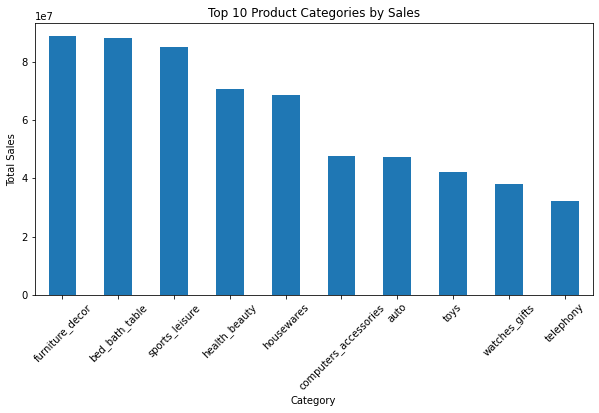

In [31]:
h5_sales.head(10)["sum"].plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.show()

In [35]:
print(products.columns.tolist())

['product_id', 'category_name', 'sub_category_name', 'product_weight_g', 'brand', 'cost_price', 'selling_price', 'stock_availability', 'selling_price_<_cost_price', 'profit', 'profit_margin', 'column1', 'unnamed:_12', 'unnamed:_13', 'unnamed:_14', 'unnamed:_15']


In [36]:
order_items["profit"] = (
    order_items["net_product_amount"]
    - order_items["total_cost_including_shipping"]
)

In [37]:
h6_data = order_items.merge(
    products[["product_id", "category_name"]],
    on="product_id",
    how="left"
)

In [38]:
h6_summary = h6_data.groupby(
    "category_name"
)["profit"].agg(
    ["count", "mean", "median", "sum"]
).sort_values(
    "mean",
    ascending=False
)

print(h6_summary)

                                   count          mean     median         sum
category_name                                                                
books_imported                       289   -165.314083   -145.530   -47775.77
fashion_childrens_clothes             57   -178.284737   -161.620   -10162.23
books_general_interest              2033   -185.589061   -162.870  -377302.56
stationery                          8388   -189.585135   -162.620 -1590240.11
books_technical                     1225   -220.267510   -193.860  -269827.70
...                                  ...           ...        ...         ...
furniture_bedroom                     39  -5860.596923  -4390.140  -228563.28
furniture_mattress_and_upholstery     13  -5934.949231  -1921.280   -77154.34
furniture_living_room                110  -6431.021364  -4284.830  -707412.35
home_confort                         110  -6613.418727  -2953.005  -727476.06
home_comfort_2                         5 -14414.252000 -16827.36

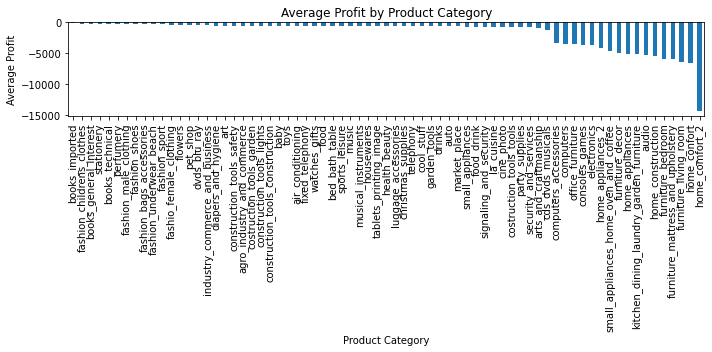

In [40]:
h6_summary["mean"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Average Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Profit")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [41]:
h7_data = profit_data[
    ["discount(%)", "profit"]
].dropna()

correlation = h7_data[
    "discount(%)"
].corr(
    h7_data["profit"]
)

print("Discount-Profit Correlation:", correlation)

Discount-Profit Correlation: -0.5044666006397452


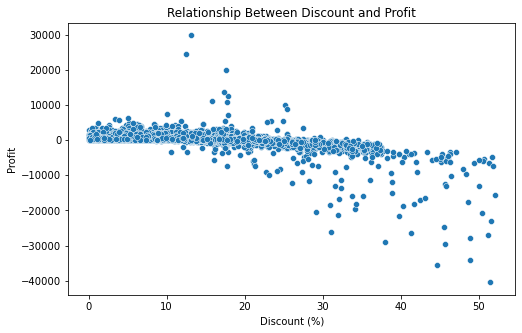

In [42]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=h7_data.sample(
        min(5000, len(h7_data)),
        random_state=42
    ),
    x="discount(%)",
    y="profit"
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Profit")

plt.show()

In [43]:
if correlation < 0:
    print(
        "Higher discounts are associated "
        "with lower profit."
    )
else:
    print(
        "The data does not show a negative "
        "discount-profit relationship."
    )

Higher discounts are associated with lower profit.


In [44]:
h8_data = reviews.merge(
    orders[
        ["order_id", "customer_id"]
    ],
    on="order_id",
    how="inner"
)

In [45]:
customer_order_count = (
    orders.groupby("customer_id")
    ["order_id"]
    .nunique()
)

h8_data["order_count"] = (
    h8_data["customer_id"]
    .map(customer_order_count)
)

h8_data["repeat_customer"] = (
    h8_data["order_count"] > 1
).astype(int)

In [46]:
h8_data["review_score"] = pd.to_numeric(
    h8_data["review_score"],
    errors="coerce"
)

In [47]:
print(
    h8_data.groupby("repeat_customer")
    ["review_score"]
    .agg(["count", "mean", "median"])
)

                 count      mean  median
repeat_customer                         
0                24972  4.100753     5.0
1                72047  4.087360     5.0


In [48]:
h9_data = orders[
    ["order_id", "delivery_delay"]
].merge(
    reviews[
        ["order_id", "review_score"]
    ],
    on="order_id",
    how="inner"
)

In [49]:
h9_data["delivery_delay"] = pd.to_numeric(
    h9_data["delivery_delay"],
    errors="coerce"
)

h9_data["review_score"] = pd.to_numeric(
    h9_data["review_score"],
    errors="coerce"
)

In [50]:
h9_data = h9_data.dropna()

h9_correlation = h9_data[
    "delivery_delay"
].corr(
    h9_data["review_score"]
)

print(
    "Delivery Delay-Review Score Correlation:",
    h9_correlation
)

Delivery Delay-Review Score Correlation: 0.0029575599333364713


In [53]:
customer_orders = orders.groupby(
    "customer_id"
)["order_id"].nunique()

loyalty = customer_orders.apply(
    lambda x: "Loyal Customer"
    if x > 1
    else "Non-Loyal Customer"
)

print(loyalty.value_counts())

Loyal Customer        26175
Non-Loyal Customer    25720
Name: order_id, dtype: int64


In [54]:
h10_data = orders[
    ["order_id", "customer_id"]
].merge(
    order_items[
        ["order_id", "net_product_amount"]
    ],
    on="order_id",
    how="inner"
)

In [55]:
customer_revenue = h10_data.groupby(
    "customer_id"
)["net_product_amount"].sum()

In [56]:
h10_result = pd.DataFrame({
    "revenue": customer_revenue,
    "loyalty": loyalty
}).dropna()

In [57]:
h10_summary = h10_result.groupby(
    "loyalty"
)["revenue"].agg(
    ["count", "mean", "median", "sum"]
)

print(h10_summary)

                    count          mean     median           sum
loyalty                                                         
Loyal Customer      24343  29113.190549  23014.919  7.087024e+08
Non-Loyal Customer  17076  14392.803325  11095.835  2.457715e+08


In [58]:
loyal_revenue = h10_result.loc[
    h10_result["loyalty"] == "Loyal Customer",
    "revenue"
]

non_loyal_revenue = h10_result.loc[
    h10_result["loyalty"] == "Non-Loyal Customer",
    "revenue"
]

t_stat_h10, p_value_h10 = stats.ttest_ind(
    loyal_revenue,
    non_loyal_revenue,
    equal_var=False
)

print("T-statistic:", t_stat_h10)
print("P-value:", p_value_h10)

if p_value_h10 < 0.05:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to Reject H0")

T-statistic: 81.35092602593404
P-value: 0.0
Decision: Reject H0


In [59]:
total_orders = orders["order_id"].nunique()

cancelled_orders = orders.loc[
    orders["is_cancelled"] == 1,
    "order_id"
].nunique()

p_cancellation = (
    cancelled_orders / total_orders
)

print(
    "Cancellation Probability:",
    round(p_cancellation * 100, 2),
    "%"
)

Cancellation Probability: 5.05 %


In [60]:
total_customers = customer_orders.shape[0]

repeat_customers = (
    customer_orders > 1
).sum()

p_repeat = (
    repeat_customers / total_customers
)

print(
    "Repeat Customer Probability:",
    round(p_repeat * 100, 2),
    "%"
)

Repeat Customer Probability: 50.44 %


In [61]:
final_validation = pd.DataFrame({
    "Hypothesis": [
        "H1: Delivery Delay → Cancellation",
        "H2: Discount → Profit"
    ],

    "Test": [
        "Two-Proportion Z-Test",
        "Welch's Independent T-Test"
    ],

    "Test Statistic": [
        z_stat,
        t_stat
    ],

    "P-value": [
        z_pvalue,
        t_pvalue
    ],

    "Alpha": [
        0.05,
        0.05
    ],

    "Decision": [
        "Reject H0"
        if z_pvalue < 0.05
        else "Fail to Reject H0",

        "Reject H0"
        if t_pvalue < 0.05
        else "Fail to Reject H0"
    ]
})

print(final_validation)

                          Hypothesis                        Test  \
0  H1: Delivery Delay → Cancellation       Two-Proportion Z-Test   
1              H2: Discount → Profit  Welch's Independent T-Test   

   Test Statistic  P-value  Alpha           Decision  
0     -103.150021      1.0   0.05  Fail to Reject H0  
1       89.906498      0.0   0.05          Reject H0  


In [73]:
import pandas as pd
import numpy as np

# ============================================================
# CREATE H1-H10 HYPOTHESIS SUMMARY
# ============================================================

hypothesis_summary = pd.DataFrame({
    "Hypothesis": [
        "H1: Delivery Delay → Cancellation",
        "H2: Discount → Profit",
        "H3: Delivery Delay → Customer Satisfaction",
        "H4: Repeat Customers → Higher Revenue",
        "H5: Product Category → Sales",
        "H6: Product Category → Profitability",
        "H7: Higher Discount → Lower Profit",
        "H8: Review Score → Repeat Purchase",
        "H9: Delivery Performance → Review Score",
        "H10: Loyal Customers → Higher Revenue"
    ],

    "Null Hypothesis (H0)": [
        "There is no significant difference in cancellation rates between delayed and on-time orders.",
        "There is no significant difference in mean profit between low/moderate and high discount groups.",
        "Average review score is the same for delayed and on-time orders.",
        "Repeat and one-time customers have the same average revenue.",
        "Sales are the same across product categories.",
        "Average profitability is the same across product categories.",
        "Discount percentage has no relationship with profit.",
        "Review score has no relationship with repeat purchasing.",
        "Delivery delay has no relationship with review score.",
        "Loyal and non-loyal customers generate the same revenue."
    ],

    "Alternative Hypothesis (H1)": [
        "Delayed orders have a higher cancellation rate.",
        "Mean profit differs between low/moderate and high discount groups.",
        "Average review score differs between delayed and on-time orders.",
        "Repeat customers generate higher average revenue.",
        "Sales differ across product categories.",
        "Profitability differs across product categories.",
        "Higher discounts are associated with lower profit.",
        "Higher review scores are associated with repeat purchasing.",
        "Delivery delay is associated with review score.",
        "Loyal customers generate higher average revenue."
    ],

    "Statistical Test / Analysis": [
        "Two-Proportion Z-Test",
        "Welch's Independent T-Test",
        "Independent T-Test",
        "Descriptive Comparison",
        "Category-wise Sales Analysis",
        "Category-wise Profit Analysis",
        "Correlation Analysis",
        "Group Comparison",
        "Correlation Analysis",
        "Welch's Independent T-Test"
    ],

    "Test Statistic": [
        z_stat if "z_stat" in globals() else np.nan,
        t_stat if "t_stat" in globals() else np.nan,
        h3_t if "h3_t" in globals() else np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        t_stat_h10 if "t_stat_h10" in globals() else np.nan
    ],

    "P-value": [
        z_pvalue if "z_pvalue" in globals() else np.nan,
        t_pvalue if "t_pvalue" in globals() else np.nan,
        h3_p if "h3_p" in globals() else np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        np.nan,
        p_value_h10 if "p_value_h10" in globals() else np.nan
    ]
})

# Add decision column
hypothesis_summary["Decision"] = hypothesis_summary["P-value"].apply(
    lambda p:
        "Reject H0" if pd.notna(p) and p < 0.05
        else "Fail to Reject H0" if pd.notna(p)
        else "Descriptive Analysis"
)

# ============================================================
# CREATE EXCEL FILE
# ============================================================

file_name = "Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx"

with pd.ExcelWriter(
    file_name,
    engine="openpyxl"
) as writer:

    # All 10 hypotheses
    hypothesis_summary.to_excel(
        writer,
        sheet_name="H1_H10_Summary",
        index=False
    )

    # Existing detailed results
    h1_summary.to_excel(
        writer,
        sheet_name="H1_Z_Test"
    )

    h2_summary.to_excel(
        writer,
        sheet_name="H2_T_Test"
    )

    # H3
    if "h3_summary" in globals():
        h3_summary.to_excel(
            writer,
            sheet_name="H3_Delivery_Reviews"
        )

    # H4
    if "h4_summary" in globals():
        h4_summary.to_excel(
            writer,
            sheet_name="H4_Repeat_Revenue"
        )

    # H5
    h5_sales.to_excel(
        writer,
        sheet_name="H5_Category_Sales"
    )

    # H6
    h6_summary.to_excel(
        writer,
        sheet_name="H6_Category_Profit"
    )

    # H7
    if "correlation" in globals():
        pd.DataFrame({
            "Metric": ["Discount-Profit Correlation"],
            "Value": [correlation]
        }).to_excel(
            writer,
            sheet_name="H7_Discount_Profit",
            index=False
        )

    # H8
    if "h8_data" in globals():
        h8_summary = h8_data.groupby(
            "repeat_customer"
        )["review_score"].agg(
            ["count", "mean", "median"]
        )

        h8_summary.to_excel(
            writer,
            sheet_name="H8_Review_Repeat"
        )

    # H9
    if "h9_correlation" in globals():
        pd.DataFrame({
            "Metric": ["Delivery Delay-Review Score Correlation"],
            "Value": [h9_correlation]
        }).to_excel(
            writer,
            sheet_name="H9_Delivery_Reviews",
            index=False
        )

    # H10
    if "h10_summary" in globals():
        h10_summary.to_excel(
            writer,
            sheet_name="H10_Loyalty_Revenue"
        )

    # Final validation
    final_validation.to_excel(
        writer,
        sheet_name="Final_Validation",
        index=False
    )

print("Excel report created successfully!")
print("File name:", file_name)

Excel report created successfully!
File name: Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx


In [77]:
from IPython.display import FileLink, display

display(FileLink(file_name))

/home/e1f01d6e-9a4f-4780-a587-0a272bcbec9e/Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx

In [79]:
import os

print(os.path.abspath("Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx"))

/home/e1f01d6e-9a4f-4780-a587-0a272bcbec9e/Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx


In [80]:
from IPython.display import Javascript, display
import base64

with open("Phase_8_Statistical_Validation_All_10_Hypotheses.xlsx", "rb") as f:
    data = base64.b64encode(f.read()).decode()

display(Javascript(f"""
var link = document.createElement('a');
link.href = 'data:application/vnd.openxmlformats-officedocument.spreadsheetml.sheet;base64,{data}';
link.download = 'Phase_8_Statistical_Validation.xlsx';
document.body.appendChild(link);
link.click();
link.remove();
"""))

<IPython.core.display.Javascript object>